# Sydney hourly weather: exploratory data analysis

This notebook characterises the Open-Meteo hourly weather observations used in UTS 36120 Advanced ML Assessment Task 2. It is an **exploratory** notebook: it does not construct targets, engineer model features, or alter the raw source file.

## Questions addressed

- What period and variables are available, and are any values missing or duplicated?
- How do the weather variables distribute, co-vary, and change through time and seasons?
- Are there tail events, zeros, daylight-saving irregularities, or data limitations that matter before daily target construction?

## Data scope

The source is `data/raw/sydney_hourly.csv`, an Open-Meteo Historical Weather API extract for Sydney (`-33.8688`, `151.2093`) in the `Australia/Sydney` timezone. It contains **87,672 hourly observations** from **2016-01-01 00:00** to **2025-12-31 23:00**: ten complete years at 24 rows per calendar day. Raw data remain immutable.

Timestamps are naive local clock times. Although Sydney observes daylight saving, this extract has a regular 24-hour grid; the temporal-integrity section verifies this explicitly. The data contain all seven weather variables required for the Climate Comfort Index (CCI) and Weather Hazard Category (WHC) formulas in the current assessment brief.

The assignment workflow aggregates hourly observations to daily values before target scoring. Therefore, plots here are descriptive only and do not apply the target formulas.

## Data dictionary

| Column | Type | Unit | Description | Target role |
|---|---|---:|---|---|
| `time` | datetime | local time | Hour beginning in Sydney local clock time | Temporal index |
| `temperature_2m` | float | °C | Air temperature at 2 metres above ground | CCI and WHC |
| `relative_humidity_2m` | integer | % | Relative humidity at 2 metres above ground | CCI |
| `wind_speed_10m` | float | km/h | Wind speed at 10 metres above ground | CCI |
| `cloud_cover` | integer | % | Fraction of sky covered by cloud | CCI and WHC |
| `precipitation` | float | mm | Total hourly precipitation | CCI and WHC |
| `wind_gusts_10m` | float | km/h | Maximum wind gust at 10 metres | WHC |
| `snowfall` | float | cm | Total hourly snowfall; the Open-Meteo unit is centimetres | WHC |

The EDA confirms the schema and completeness programmatically in the following section.

In [8]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.2f}".format)


def project_root(start: Path | None = None) -> Path:
    """Return the project directory containing ``pyproject.toml``."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current directory.")


PROJECT_ROOT = project_root()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "sydney_hourly.csv"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

WEATHER_COLUMNS = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "cloud_cover",
    "precipitation",
    "wind_gusts_10m",
    "snowfall",
]
DISPLAY_NAMES = {
    "temperature_2m": "Temperature (°C)",
    "relative_humidity_2m": "Relative humidity (%)",
    "wind_speed_10m": "Wind speed (km/h)",
    "cloud_cover": "Cloud cover (%)",
    "precipitation": "Precipitation (mm/h)",
    "wind_gusts_10m": "Wind gusts (km/h)",
    "snowfall": "Snowfall (cm/h)",
}

## Load and validate the source

The CSV is read without modification. Validation checks make data-quality assumptions visible before any downstream daily aggregation.

In [15]:
hourly = pd.read_csv(DATA_PATH, parse_dates=["time"])

In [9]:
hourly = pd.read_csv(DATA_PATH, parse_dates=["time"])

missing_columns = sorted(set(["time", *WEATHER_COLUMNS]) - set(hourly.columns))
if missing_columns:
    raise ValueError(f"Source is missing expected columns: {missing_columns}")

hourly = hourly.sort_values("time").reset_index(drop=True)

print(f"Source: {DATA_PATH.relative_to(PROJECT_ROOT)}")
print(f"Rows: {len(hourly):,}")
print(f"Window: {hourly['time'].min():%Y-%m-%d %H:%M} to {hourly['time'].max():%Y-%m-%d %H:%M}")
print(f"Duplicate timestamps: {hourly['time'].duplicated().sum():,}")
hourly.head()

Source: data/raw/sydney_hourly.csv
Rows: 87,672
Window: 2016-01-01 00:00 to 2025-12-31 23:00
Duplicate timestamps: 0


,time,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall
0,2016-01-01 00:00:00,18.30,81,5.60,42,0.00,11.50,0.00
1,2016-01-01 01:00:00,18.00,82,5.90,65,0.00,11.20,0.00
2,2016-01-01 02:00:00,17.70,84,6.80,93,0.00,11.20,0.00
3,2016-01-01 03:00:00,16.80,89,4.70,67,0.00,9.00,0.00
4,2016-01-01 04:00:00,16.60,88,2.40,39,0.00,6.80,0.00


## Completeness and descriptive statistics

Missing values are reported separately from the expected daylight-saving changes in clock hours. Descriptive statistics include high quantiles to reveal the events that means and standard deviations can hide.

In [17]:
quality = pd.DataFrame(
    {
        "non_null": hourly[WEATHER_COLUMNS].notna().sum(),
        "missing": hourly[WEATHER_COLUMNS].isna().sum(),
        "missing_pct": hourly[WEATHER_COLUMNS].isna().mean().mul(100),
        "zero_pct": hourly[WEATHER_COLUMNS].eq(0).mean().mul(100),
    }
)
quality

summary = hourly[WEATHER_COLUMNS].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T
summary[["min", "1%", "mean", "50%", "95%", "99%", "max"]]

,min,1%,mean,50%,95%,99%,max
temperature_2m,1.10,6.40,17.64,17.80,26.10,30.30,42.00
relative_humidity_2m,9.00,28.00,73.04,75.00,96.00,99.00,100.00
wind_speed_10m,0.00,2.10,12.93,11.80,25.60,31.40,48.80
cloud_cover,0.00,0.00,48.93,45.00,100.00,100.00,100.00
precipitation,0.00,0.00,0.12,0.00,0.60,2.40,19.70
wind_gusts_10m,1.40,6.50,27.70,25.60,52.20,64.10,102.20
snowfall,0.00,0.00,0.00,0.00,0.00,0.00,0.00


## Time coverage and daylight saving

Sydney's local clock has 23-hour and 25-hour days at daylight-saving transitions. These are expected where the dataset uses naive local timestamps; missing or duplicate timestamps outside those dates require investigation before daily aggregation.

Missing clock hours across the full grid: 0
Days with a non-24-hour local clock:


,hour_count
time,


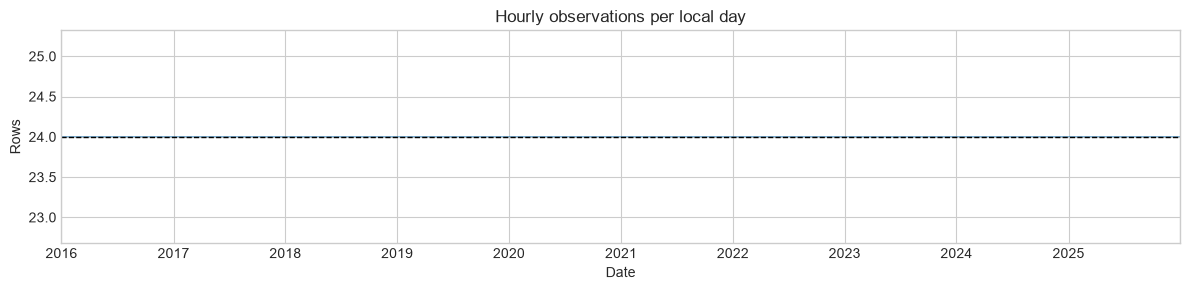

In [18]:
expected_hours = pd.date_range(hourly["time"].min(), hourly["time"].max(), freq="h")
observed_hours = pd.DatetimeIndex(hourly["time"])
missing_hours = expected_hours.difference(observed_hours)

hours_per_day = hourly.groupby(hourly["time"].dt.normalize()).size()
irregular_days = hours_per_day.loc[hours_per_day.ne(24)]

print(f"Missing clock hours across the full grid: {len(missing_hours):,}")
print("Days with a non-24-hour local clock:")
display(irregular_days.to_frame("hour_count"))

fig, ax = plt.subplots(figsize=(12, 3))
hours_per_day.plot(ax=ax, lw=0.5)
ax.axhline(24, color="black", ls="--", lw=1)
ax.set(title="Hourly observations per local day", xlabel="Date", ylabel="Rows")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eda-hours-per-day.png", dpi=160, bbox_inches="tight")
plt.show()

## Long-run behaviour and distributions

Monthly averages make seasonality and potential trend changes legible. Histograms use the raw hourly scale; precipitation and snowfall are separated because their many zero values would obscure the other variables.

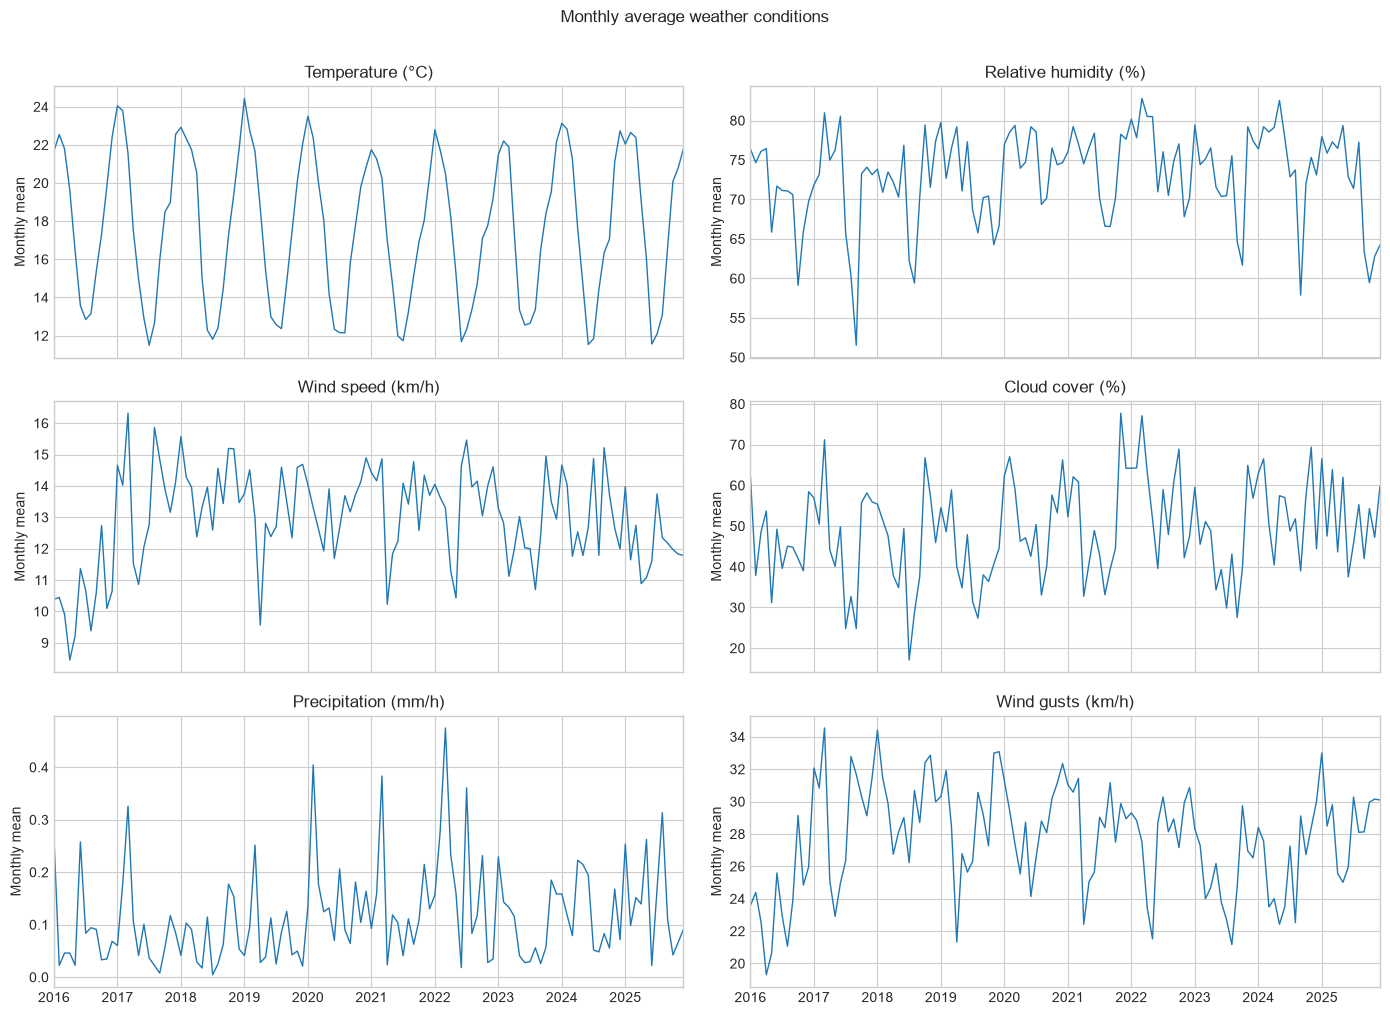

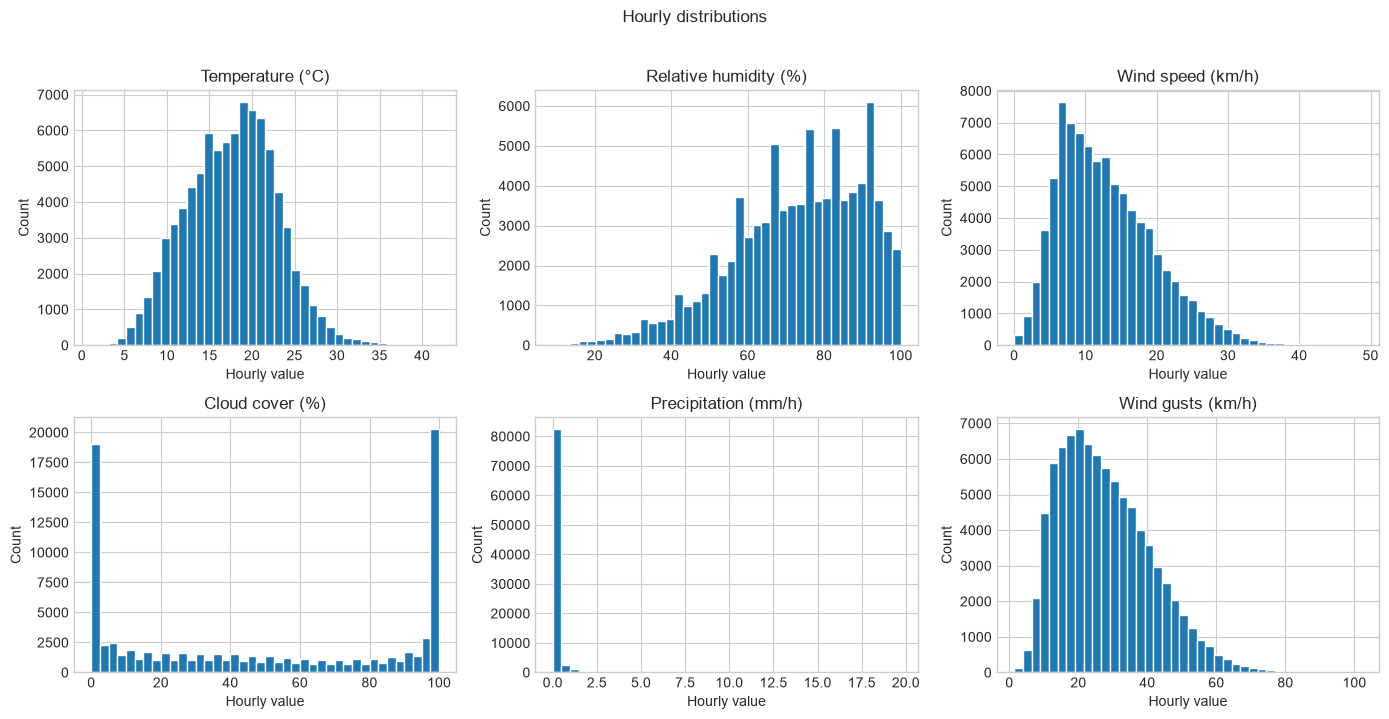

In [12]:
monthly = hourly.set_index("time")[WEATHER_COLUMNS].resample("MS").mean()
plot_columns = [column for column in WEATHER_COLUMNS if column != "snowfall"]

fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)
for ax, column in zip(axes.ravel(), plot_columns, strict=True):
    monthly[column].plot(ax=ax, color="tab:blue", lw=1)
    ax.set(title=DISPLAY_NAMES[column], xlabel="", ylabel="Monthly mean")
fig.suptitle("Monthly average weather conditions", y=1.01)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eda-monthly-conditions.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, column in zip(axes.ravel(), plot_columns, strict=True):
    hourly[column].dropna().plot.hist(ax=ax, bins=40, color="tab:blue", edgecolor="white")
    ax.set(title=DISPLAY_NAMES[column], xlabel="Hourly value", ylabel="Count")
fig.suptitle("Hourly distributions", y=1.02)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eda-hourly-distributions.png", dpi=160, bbox_inches="tight")
plt.show()

## Seasonal profiles and variable relationships

Seasonal profiles are calculated by month of year. The correlation matrix is descriptive, using Pearson correlation on contemporaneous hourly records; it must not be interpreted as a predictive relationship or used to justify leakage.

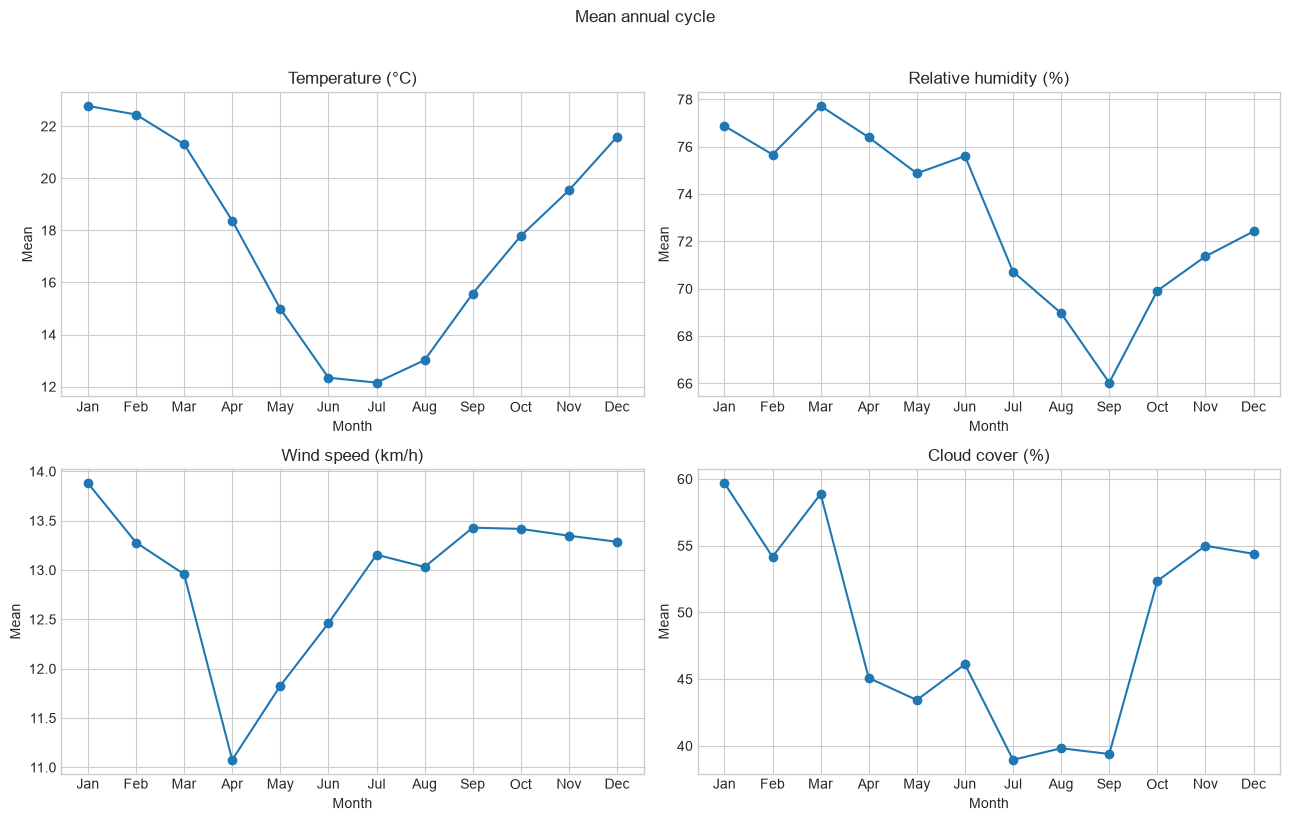

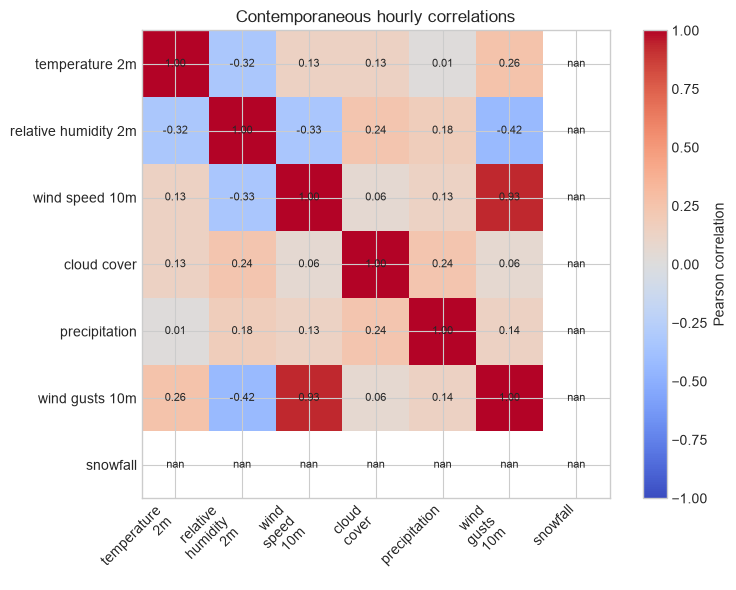

,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall
temperature_2m,1.00,-0.32,0.13,0.13,0.01,0.26,NaN
relative_humidity_2m,-0.32,1.00,-0.33,0.24,0.18,-0.42,NaN
wind_speed_10m,0.13,-0.33,1.00,0.06,0.13,0.93,NaN
cloud_cover,0.13,0.24,0.06,1.00,0.24,0.06,NaN
precipitation,0.01,0.18,0.13,0.24,1.00,0.14,NaN
wind_gusts_10m,0.26,-0.42,0.93,0.06,0.14,1.00,NaN
snowfall,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
monthly_climatology = hourly.groupby(hourly["time"].dt.month)[WEATHER_COLUMNS].mean()
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, column in zip(
    axes.ravel(), ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "cloud_cover"], strict=True
):
    monthly_climatology[column].plot(ax=ax, marker="o", color="tab:blue")
    ax.set(title=DISPLAY_NAMES[column], xlabel="Month", ylabel="Mean")
    ax.set_xticks(range(1, 13), month_labels)
fig.suptitle("Mean annual cycle", y=1.02)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eda-seasonal-cycle.png", dpi=160, bbox_inches="tight")
plt.show()

correlations = hourly[WEATHER_COLUMNS].corr()
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(WEATHER_COLUMNS)), [column.replace("_", "\n") for column in WEATHER_COLUMNS], rotation=45, ha="right")
ax.set_yticks(range(len(WEATHER_COLUMNS)), [column.replace("_", " ") for column in WEATHER_COLUMNS])
for row in range(len(correlations)):
    for column in range(len(correlations)):
        ax.text(column, row, f"{correlations.iloc[row, column]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Contemporaneous hourly correlations")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eda-correlations.png", dpi=160, bbox_inches="tight")
plt.show()

correlations

## Rare events and target-relevant limitations

The following checks flag characteristics that affect daily target construction. They do not calculate a target. In particular, Sydney snowfall may have no variation, and rainfall/gust tails should be reviewed after aggregation at the daily scale required by the brief.

Maximum observed hourly snowfall: 0.00 cm
Snowfall has 1 unique non-null value(s).
Days with precipitation ≥20 mm: 115
Days with precipitation ≥30 mm: 51
Days with gusts ≥100 km/h: 1


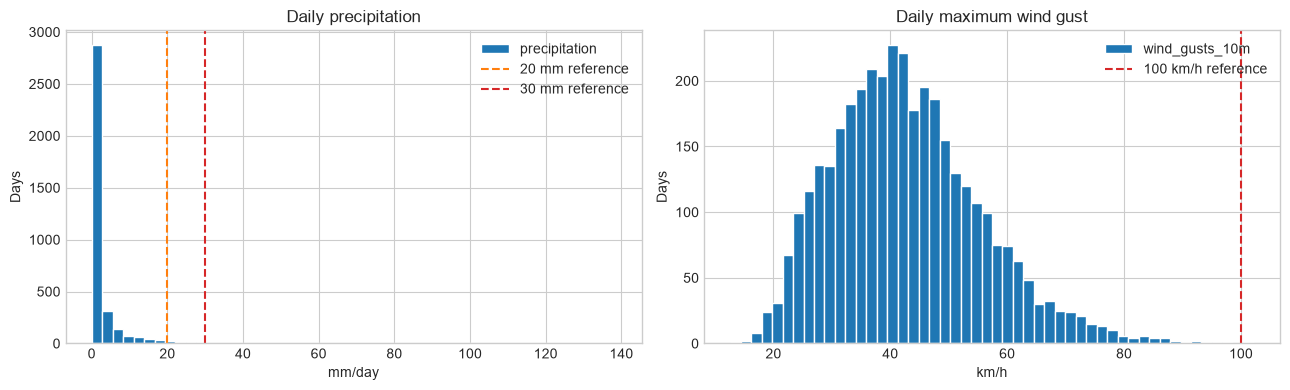

In [14]:
daily_for_eda = (
    hourly.set_index("time")
    .resample("D")
    .agg(
        precipitation=("precipitation", "sum"),
        wind_gusts_10m=("wind_gusts_10m", "max"),
        snowfall=("snowfall", "sum"),
    )
)

print(f"Maximum observed hourly snowfall: {hourly['snowfall'].max():.2f} cm")
print(f"Snowfall has {hourly['snowfall'].nunique(dropna=True)} unique non-null value(s).")
print(f"Days with precipitation ≥20 mm: {(daily_for_eda['precipitation'] >= 20).sum():,}")
print(f"Days with precipitation ≥30 mm: {(daily_for_eda['precipitation'] >= 30).sum():,}")
print(f"Days with gusts ≥100 km/h: {(daily_for_eda['wind_gusts_10m'] >= 100).sum():,}")

daily_for_eda[["precipitation", "wind_gusts_10m"]].quantile([0.5, 0.9, 0.95, 0.99, 1.0]).T

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
daily_for_eda["precipitation"].plot.hist(ax=axes[0], bins=50, color="tab:blue", edgecolor="white")
axes[0].axvline(20, color="tab:orange", ls="--", label="20 mm reference")
axes[0].axvline(30, color="tab:red", ls="--", label="30 mm reference")
axes[0].set(title="Daily precipitation", xlabel="mm/day", ylabel="Days")
axes[0].legend()

daily_for_eda["wind_gusts_10m"].plot.hist(ax=axes[1], bins=50, color="tab:blue", edgecolor="white")
axes[1].axvline(100, color="tab:red", ls="--", label="100 km/h reference")
axes[1].set(title="Daily maximum wind gust", xlabel="km/h", ylabel="Days")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eda-daily-tail-events.png", dpi=160, bbox_inches="tight")
plt.show()

## EDA conclusions and next steps

Run the cells above and replace this checklist with report-facing observations supported by the displayed values and figures.

- Confirm that required source columns are complete and that timestamp irregularities align only with Sydney daylight-saving transitions.
- Treat rainfall, snowfall, and extreme gusts as potentially sparse or zero-inflated; assess their distributions again after daily aggregation.
- Snowfall has no variation in this Sydney source, so its WHC hazard component is constant; report its consequence for the class distribution.
- Preserve time order. Any later lagged or rolling predictor must only use day *t* and earlier, while targets are shifted to their required future horizons.

The CCI and WHC preprocessing notebooks write daily aggregates to `data/interim/`, calculate targets from those daily values, and retain only rows with a complete future target window.